# Data Preprocessing: Market Basket Dataset
**Praktikum Data Mining - Tahap Data Understanding & Preprocessing**

* **Dataset:** `market_basket_dataset.csv`
* **Karakteristik Data:** 1.500 transaksi keranjang belanja dan 10 produk ritel.
* **Fokus Analisis:**
  1. Pemeriksaan Dimensi Data (Record & Atribut)
  2. Analisis Missing Value dan Visualisasi Heatmap
  3. Penanganan Missing Value dengan Transformasi Matriks Biner (One-Hot Encoding)
  4. Analisis Data Duplikat Transaksi


## 1. Import Library & Load Dataset


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 5)

df = pd.read_csv('market_basket_dataset.csv')
print("Dataset berhasil dibaca!")


Dataset berhasil dibaca!


## 2. Eksplorasi Data Awal (Head & Tail)


In [2]:
display(df.head())
display(df.tail())


,Milk,Bread,Butter,Cheese,Eggs,Juice,Chips,Soda,Chicken,Apples
0,Milk,NaN,Butter,NaN,Eggs,Juice,Chips,Soda,NaN,Apples
1,NaN,NaN,Butter,NaN,NaN,Juice,Chips,NaN,NaN,Apples
2,Milk,NaN,NaN,NaN,NaN,Juice,NaN,Soda,NaN,Apples
3,NaN,NaN,Butter,NaN,Eggs,Juice,NaN,Soda,Chicken,NaN
4,NaN,Bread,Butter,NaN,Eggs,Juice,Chips,NaN,NaN,Apples


,Milk,Bread,Butter,Cheese,Eggs,Juice,Chips,Soda,Chicken,Apples
1495,NaN,NaN,NaN,NaN,Eggs,Juice,NaN,NaN,NaN,NaN
1496,Milk,NaN,NaN,NaN,Eggs,NaN,Chips,NaN,NaN,NaN
1497,NaN,NaN,NaN,Cheese,Eggs,NaN,Chips,Soda,Chicken,NaN
1498,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1499,Milk,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Chicken,NaN


## 3. Pemeriksaan Dimensi Data


In [3]:
print("Jumlah Record (Transaksi) :", df.shape[0])
print("Jumlah Atribut (Produk)   :", df.shape[1])


Jumlah Record (Transaksi) : 1500
Jumlah Atribut (Produk)   : 10


## 4. Frekuensi Pembelian per Produk


In [4]:
jumlah_terisi = df.count()
print("Jumlah Produk Terisi Setiap Atribut:")
display(jumlah_terisi.to_frame(name='Frekuensi Pembelian'))


Jumlah Produk Terisi Setiap Atribut:


,Frekuensi Pembelian
Milk,635
Bread,622
Butter,647
Cheese,623
Eggs,643
Juice,636
Chips,657
Soda,634
Chicken,606
Apples,627


## 5. Pemeriksaan Missing Value & Persentase


In [5]:
missing_count = df.isnull().sum()
missing_pct = (df.isnull().sum() / len(df) * 100).round(2)

tabel_missing = pd.DataFrame({
    'Jumlah Missing Value': missing_count,
    'Persentase (%)': missing_pct
})

print("Tabel Missing Value per Atribut:")
display(tabel_missing)
print("Total Missing Value di Seluruh Data:", df.isnull().sum().sum())


Tabel Missing Value per Atribut:


,Jumlah Missing Value,Persentase (%)
Milk,865,57.67
Bread,878,58.53
Butter,853,56.87
Cheese,877,58.47
Eggs,857,57.13
Juice,864,57.60
Chips,843,56.20
Soda,866,57.73
Chicken,894,59.60
Apples,873,58.20


Total Missing Value di Seluruh Data: 8670


## 6. Visualisasi Heatmap Missing Value Sebelum Transformasi


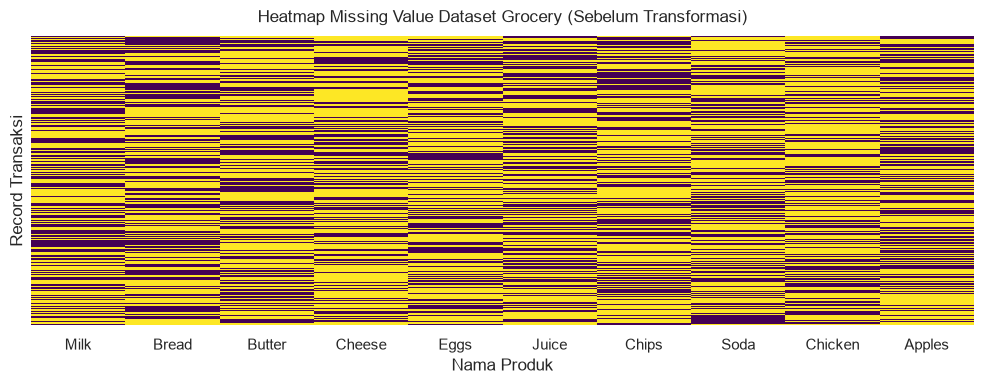

In [6]:
plt.figure(figsize=(10, 4))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Heatmap Missing Value Dataset Grocery (Sebelum Transformasi)', fontsize=12, pad=10)
plt.xlabel('Nama Produk')
plt.ylabel('Record Transaksi')
plt.tight_layout()
plt.show()


## 7. Penanganan Missing Value: Transformasi Matriks Biner


In [7]:
df_apriori = df.notna().astype(int)

print("Dataset Setelah Transformasi Biner:")
display(df_apriori.head())
print("Jumlah Missing Value Setelah Transformasi:", df_apriori.isnull().sum().sum())


Dataset Setelah Transformasi Biner:


,Milk,Bread,Butter,Cheese,Eggs,Juice,Chips,Soda,Chicken,Apples
0,1,0,1,0,1,1,1,1,0,1
1,0,0,1,0,0,1,1,0,0,1
2,1,0,0,0,0,1,0,1,0,1
3,0,0,1,0,1,1,0,1,1,0
4,0,1,1,0,1,1,1,0,0,1


Jumlah Missing Value Setelah Transformasi: 0


## 8. Visualisasi Heatmap Setelah Transformasi Biner


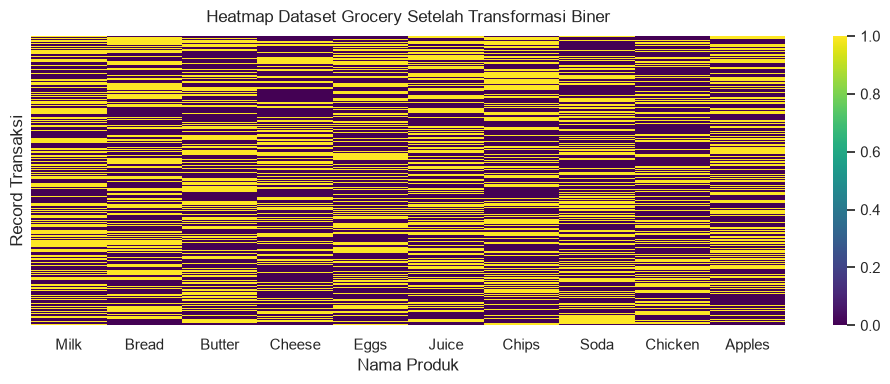

In [8]:
plt.figure(figsize=(10, 4))
sns.heatmap(df_apriori, cbar=True, cmap='viridis', yticklabels=False)
plt.title('Heatmap Dataset Grocery Setelah Transformasi Biner', fontsize=12, pad=10)
plt.xlabel('Nama Produk')
plt.ylabel('Record Transaksi')
plt.tight_layout()
plt.show()


## 9. Verifikasi Missing Value Setelah Penanganan


In [9]:
print("Pemeriksaan Missing Value Setiap Atribut:")
display(df_apriori.isnull().sum().to_frame(name='Jumlah Missing'))
print("Total Missing Value Setelah Transformasi:", df_apriori.isnull().sum().sum())


Pemeriksaan Missing Value Setiap Atribut:


,Jumlah Missing
Milk,0
Bread,0
Butter,0
Cheese,0
Eggs,0
Juice,0
Chips,0
Soda,0
Chicken,0
Apples,0


Total Missing Value Setelah Transformasi: 0


## 10. Analisis Data Duplikat


In [10]:
jumlah_duplikat = df.duplicated().sum()
persen_duplikat = (jumlah_duplikat / len(df) * 100).round(2)

print(f"Jumlah Data Duplikat : {jumlah_duplikat} transaksi")
print(f"Persentase Duplikat  : {persen_duplikat}%")


Jumlah Data Duplikat : 774 transaksi
Persentase Duplikat  : 51.6%
